# Cointegration | Frozen pair strategy

Pairs were formed and trained during 2022-2025; the saved 2026 deployment uses **288 frozen pairs**. This notebook is separate from Market Neutral.

The legacy record contains summary statistics without daily NAV. Historical-RF Sharpe cannot be reconstructed reliably from those aggregates, so the old RF=0 Sharpe is withdrawn and shown as **Not verified**. Default execution only reads the saved record.

[Project research report](report.html#cointegration) | [Parameters](result/cointegration/frozen2026/parameters.py)

In [1]:
from pathlib import Path
import json, runpy, sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "methods/aqr_factors/run.py").is_file())
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": .2})

PARAMETER_FILE = PROJECT / "result/cointegration/frozen2026/parameters.py"
RERUN = False  # True replays the frozen pool; may download missing prices, but never retrains it.
parameters = runpy.run_path(str(PARAMETER_FILE))["PARAMETERS"]
result_file = PARAMETER_FILE.with_name("result.json")
if RERUN:
    from methods.cointegration.run import run
    result = run(parameters, output=result_file)
else:
    result = json.loads(result_file.read_text(encoding="utf-8"))
backtest = result["backtest"]
print(f"Training: {result['train_start']} → {result['train_end']} | Deployment: {backtest['start']} → {backtest['end']}")


Training: 2022-01-01 → 2025-12-31 | Deployment: 2026-01-02 → 2026-10-22


In [2]:
display(pd.DataFrame(backtest["comparison"]).T[["return", "sharpe", "volatility", "max_drawdown"]].rename(columns={"return": "Cumulative return", "sharpe": "Sharpe",
    "volatility": "Annual volatility", "max_drawdown": "Max drawdown"}).style.format({"Cumulative return": "{:.2%}",
    "Sharpe": "{:.4f}", "Annual volatility": "{:.2%}", "Max drawdown": "{:.2%}"}, na_rep="Not verified"))
pnl = pd.Series({"Net P&L": backtest["cumulative_pnl"], "Realized net P&L": backtest["cumulative_net_realized_pnl"],
                 "Unrealized net P&L": backtest["net_unrealized_pnl"], "Total cost": backtest["cumulative_total_cost"]}, name="USD")
display(pnl.to_frame().style.format("{:,.2f}"))


,Cumulative return,Sharpe,Annual volatility,Max drawdown
Strategy,-3.88%,Not verified,7.15%,-8.40%
SPY,11.41%,Not verified,12.98%,-9.13%


,USD
Net P&L,"-77,532.19"
Realized net P&L,"158,883.39"
Unrealized net P&L,"-236,415.58"
Total cost,"14,228.22"


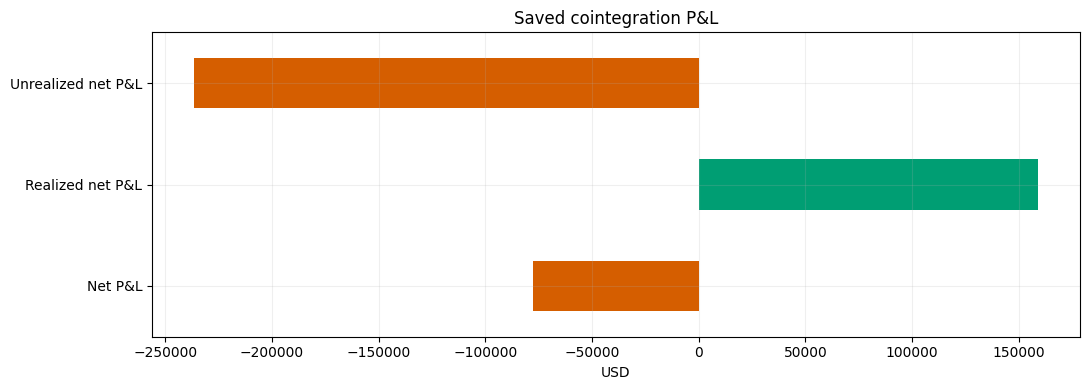

In [3]:
# Plot only this method's own daily results when available.
if "daily" in result:
    daily = pd.DataFrame(result["daily"]).set_index("Date")
    daily.index = pd.to_datetime(daily.index)
    daily[["cumulative_return", "spy_cumulative_return"]].mul(100).plot(title="Cointegration vs SPY", ylabel="Return (%)")
else:
    pnl.iloc[:3].plot.barh(title="Saved cointegration P&L", xlabel="USD", color=["#d55e00", "#009e73", "#d55e00"])
plt.tight_layout()
plt.show()


In [4]:
pool = pd.read_csv(PROJECT / "methods/cointegration/data/pool.csv")
print(f"Frozen pairs: {len(pool)} | Maximum simultaneous holdings: {parameters['backtest']['max_positions_per_side']} pairs")
display(pd.Series(parameters["backtest"], name="Execution setting").to_frame())
display(pool[["y_ticker", "x_ticker", "selection_sharpe", "entry_z", "exit_z"]].head(10))


Frozen pairs: 288 | Maximum simultaneous holdings: 15 pairs


,Execution setting
start_date,2026-01-01
end_date,2026-10-22
long_amount,1000000
short_amount,1000000
max_positions_per_side,15
execution_timing,close
borrow_fee_rate,0.01
transaction_cost_rate,0.0005
fx_financing_rate,0.0
take_profit_amount,2000


,y_ticker,x_ticker,selection_sharpe,entry_z,exit_z
0,APO,ARES,1.881164,3.0,0.0
1,AYI,POWL,1.793948,3.0,0.0
2,MS,NWG,1.727894,2.5,0.5
3,SF,AX,1.717064,3.0,0.5
4,ALSN,RUSHA,1.670571,3.0,0.0
5,BNY,SYF,1.661639,2.5,0.5
6,MTSI,FN,1.657709,2.5,0.0
7,BKNG,RCL,1.646327,3.0,0.5
8,PHYS,AMG,1.644844,2.5,0.0
9,JPM,MFG,1.639926,3.0,0.5


Each side has a $1,000,000 budget; see the preset for costs. Current company metadata introduces survivorship limitations. The 2026 results were inspected during development and are not untouched out-of-sample evidence.

Shared trading, borrow and financing cost logic lives in root `backtest.py`; pair-specific beta sizing and integer share / FX lot rounding remain in `methods/cointegration/execution.py`. An explicit replay uses historical DGS1MO; the old summary's historical-RF Sharpe remains unverified. The detailed cointegration narrative is pending; this report update completes Market Neutral first.